In [ ]:
# Manipulación de datos
import pandas as pd
import numpy as np
import kagglehub

# Visualización
import matplotlib.pyplot as plt

# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Evaluación
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score
)

# Álgebra lineal
from scipy.linalg import cho_factor, cho_solve

# Utilidades
from pathlib import Path
from time import perf_counter
from math import comb

# Configuración
EPSILON = 1e-6
PERCENTILES = [50, 75, 90, 95, 99]

DATA_DIR = Path("data")
RESULTS_DIR = Path("resultados")

RESULTS_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", None)

print("Librerías importadas correctamente")

Librerías importadas correctamente


c:\Users\Practicante2\Desktop\mcd\financial_fraud_detector\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Download latest version
path = Path(
    kagglehub.dataset_download(
        "mohankrishnathalla/credit-card-fraud-detection-dataset-2026"
    )
)

print("Path to dataset files:", path)

# Load dataset
df = pd.read_csv(
    path / "credit_card_fraud_detection_2026.csv"
)

display(df.head())

Path to dataset files: C:\Users\Practicante2\.cache\kagglehub\datasets\mohankrishnathalla\credit-card-fraud-detection-dataset-2026\versions\46


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,709,6630.0,742,2,1,2,3,88.91,209.94,0.9,13.0,0.3,0,0,0.398,0,0,Online,Mobile,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.0
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,1143,4350.0,602,1,6,6,23,1290.10,1093.31,6.6,5311.8,17.0,1,0,0.278,1,1,In-store,POS Terminal,NaN,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.0
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,601,3950.0,605,4,1,1,3,36.27,46.54,4.2,14164.5,53.2,1,0,0.925,0,0,Online,Desktop,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.0
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,0,51,Female,OH,582,13870.0,675,5,0,2,3,0.00,134.35,3.0,1119.1,3.6,1,1,0.718,0,1,ATM,ATM,NaN,0,64.87,29.76,0,0,gmail,0,Legitimate,0.0
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,711,6570.0,743,2,1,2,2,38.37,117.74,0.9,6564.5,22.4,1,0,1.317,1,0,In-store,POS Terminal,NaN,0,47.19,18.52,0,0,gmail,0,Legitimate,0.0


### Fase 3. Adquisición y preparación de los datos

In [5]:
n, d = df.shape

print(f"Número de observaciones (n): {n:,}")
print(f"Número de columnas (d): {d}")
print(f"Registros duplicados: {df.duplicated().sum():,}")

Número de observaciones (n): 100,000
Número de columnas (d): 43
Registros duplicados: 0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  object 
 1   customer_id                  100000 non-null  object 
 2   card_id                      100000 non-null  object 
 3   merchant_id                  100000 non-null  object 
 4   transaction_datetime         100000 non-null  object 
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  object 
 7   merchant_country             100000 non-null  object 
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  object 
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  object 
 13  

In [7]:
df_diagnostico = pd.DataFrame({
    "tipo_dato": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "valores_nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean() * 100
})

display(df_diagnostico)

,tipo_dato,valores_unicos,valores_nulos,porcentaje_nulos
transaction_id,object,100000,0,0.000
customer_id,object,8000,0,0.000
card_id,object,8000,0,0.000
merchant_id,object,3000,0,0.000
transaction_datetime,object,99762,0,0.000
transaction_amount,float64,30862,0,0.000
merchant_category,object,15,0,0.000
merchant_country,object,20,0,0.000
transaction_hour,int64,24,0,0.000
transaction_day_of_week,object,7,0,0.000


#### Solo hay una columna con valores nulos y es 'browser'; es decir, de qué navegador se hizo la consulta. Es una variable categórica

In [8]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
transaction_amount,100000.0,126.871977,276.180425,0.500,21.2800,52.260,129.72000,15000.000
transaction_hour,100000.0,14.393860,5.018253,0.000,11.0000,14.000,19.00000,23.000
card_present,100000.0,0.357770,0.479346,0.000,0.0000,0.000,1.00000,1.000
customer_age,100000.0,42.223670,14.246361,18.000,32.0000,42.000,52.00000,85.000
account_age_days,100000.0,785.451240,747.492434,1.000,233.0000,554.000,1103.00000,3650.000
credit_limit,100000.0,10083.182000,6510.646682,500.000,5000.0000,8500.000,13650.00000,36670.000
credit_score,100000.0,682.329280,92.122179,328.000,620.0000,683.000,748.00000,850.000
num_cards_held,100000.0,2.198830,1.163491,1.000,1.0000,2.000,3.00000,5.000
transactions_last_1h,100000.0,0.783890,1.348801,0.000,0.0000,0.000,1.00000,8.000
transactions_last_24h,100000.0,2.951760,2.382417,0.000,1.0000,2.000,4.00000,18.000


In [9]:
# Seleccionar solo México de la lista de países
df["merchant_country"].value_counts()

merchant_country
USA             44515
UK               8349
Canada           7238
Germany          5651
Australia        5423
France           4521
Italy            3344
Netherlands      3039
Spain            2849
Brazil           2354
India            2175
Mexico           1921
China            1682
Nigeria          1261
South Africa     1140
Russia           1046
Romania           943
UAE               940
Japan             821
South Korea       788
Name: count, dtype: int64

In [11]:
df_mx = df[df["merchant_country"] == "Mexico"].copy()

n, d = df_mx.shape

print(f"Transacciones en México: {n:,}")
print(f"Número de columnas: {d}")
print(f"Porcentaje del dataset original: {n / len(df):.2%}")

Transacciones en México: 1,921
Número de columnas: 43
Porcentaje del dataset original: 1.92%


,cantidad,porcentaje
is_fraud,,
0,1869,97.293077
1,52,2.706923


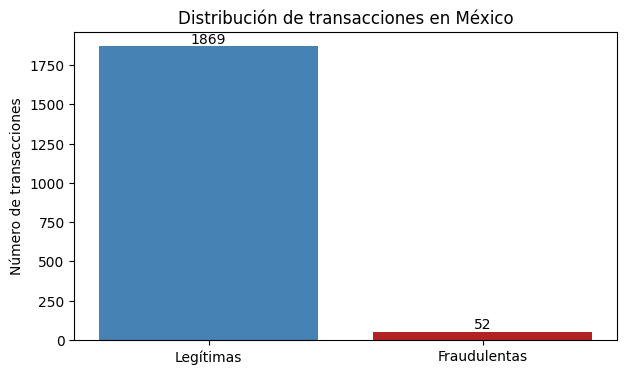

In [14]:
df_distribucion = pd.DataFrame({
    "cantidad": df_mx["is_fraud"].value_counts(),
    "porcentaje": df_mx["is_fraud"].value_counts(normalize=True) * 100
}).sort_index()

display(df_distribucion)

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ["Legítimas", "Fraudulentas"],
    df_distribucion.loc[[0, 1], "cantidad"],
    color=["steelblue", "firebrick"]
)

ax.set_title("Distribución de transacciones en México")
ax.set_ylabel("Número de transacciones")

ax.bar_label(ax.containers[0])

plt.show()

### Fase 4. Procesamiento de los datos

In [15]:
display(
    df_mx.groupby("is_fraud")["fraud_amount_lost"]
    .agg(["count", "min", "max", "mean", "std"])
)

,count,min,max,mean,std
is_fraud,,,,,
0,1869,0.00,0.00,0.000000,0.000000
1,52,3.64,1781.88,200.687692,306.026875


In [ ]:
y = df_mx["is_fraud"].copy()

X = df_mx.select_dtypes(include='number').copy()

# Excluir columnas que no se usarán como features
columnas_excluir = ["is_fraud", "fraud_amount_lost"]
X = X.drop(columns=columnas_excluir)

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

Dimensiones de X: (1921, 26)
Dimensiones de y: (1921,)


In [ ]:
# Una característica constante tiene una varianza igual a cero; por lo tanto, no aporta información para distinguir una transacción de otra.
columnas_constantes = X.columns[X.nunique() <= 1].tolist()
print("Columnas constantes:", columnas_constantes)

Columnas constantes: ['international_transaction', 'high_risk_country']


In [19]:
X = X.drop(columns=columnas_constantes)
print(f"Dimensiones finales de X: {X.shape}")

Dimensiones finales de X: (1921, 24)


In [20]:
# Validación de las estructuras
assert X.shape[0] == y.shape[0]
assert X.index.equals(y.index)
assert X.isna().sum().sum() == 0
assert np.isfinite(X.to_numpy()).all()
assert set(y.unique()) == {0, 1}

print("Validaciones exitosas.")

print(f"Número de observaciones: {X.shape[0]:,}")
print(f"Número de características: {X.shape[1]}")
print(f"Número de etiquetas: {len(y):,}")

display(X.head())

Validaciones exitosas.
Número de observaciones: 1,921
Número de características: 24
Número de etiquetas: 1,921


,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever
26,827.60,8,1,26,188,15400.0,769,1,2,2,7,147.82,166.74,1.3,6061.2,6.2,9.194,0,0,0,90.02,65.89,0,0
54,62.19,9,1,52,2129,14520.0,734,4,1,1,1,81.43,89.41,10.1,12923.8,6.3,0.616,1,0,0,100.98,46.77,0,0
61,71.10,10,0,52,143,4730.0,561,2,1,5,8,68.33,431.55,4.0,6275.5,31.3,0.895,0,0,0,79.40,58.88,0,0
74,13.63,11,0,46,387,4300.0,593,2,0,0,0,0.00,0.00,1.0,11521.2,6064.6,0.418,0,0,0,32.58,13.23,2,0
80,103.65,11,0,31,379,10650.0,671,2,0,3,3,0.00,410.89,2.3,3960.3,23.4,0.899,0,0,0,115.25,83.16,0,0


#### 4.2. División de los datos

In [ ]:
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y # Preserva aproximadamente la proporción de ambas clases en los conjuntos de entrenamiento y prueba
)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

X_train: (1536, 24)
X_test:  (385, 24)
y_train: (1536,)
y_test:  (385,)


In [24]:
df_particiones = pd.DataFrame({
    "Total": y.value_counts(),
    "Entrenamiento": y_train.value_counts(),
    "Prueba": y_test.value_counts()
}).sort_index()

df_particiones.index = ["Legítimas", "Fraudulentas"]

display(df_particiones)

df_proporciones = (
    df_particiones / df_particiones.sum()
) * 100

display(df_proporciones.round(2))

,Total,Entrenamiento,Prueba
Legítimas,1869,1494,375
Fraudulentas,52,42,10


,Total,Entrenamiento,Prueba
Legítimas,97.29,97.27,97.4
Fraudulentas,2.71,2.73,2.6


In [25]:
assert len(X_train) + len(X_test) == len(X)

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

assert X_train.index.intersection(X_test.index).empty

print("División de datos validada correctamente.")

División de datos validada correctamente.


#### 4.3. Estandarización de los datos

In [ ]:
scaler = StandardScaler()

# Ajustar y transformar el conjunto de entrenamiento: fit() calcula las medias y desviación estándar, transform() aplica la transformación a los datos y fit_transform() hace ambas
X_train_scaled = scaler.fit_transform(X_train)

# Transformar el conjunto de prueba
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_test_scaled:  {X_test_scaled.shape}")

X_train_scaled: (1536, 24)
X_test_scaled:  (385, 24)


In [29]:
df_scaler = pd.DataFrame({
    "caracteristica": X_train.columns,
    "media": scaler.mean_,
    "desviacion_estandar": scaler.scale_,
    "varianza": scaler.var_
})
print("Distribución de los datos antes de la escala:")
display(df_scaler.round(4))

Distribución de los datos antes de la escala:


,caracteristica,media,desviacion_estandar,varianza
0,transaction_amount,157.2592,342.5759,1.173582e+05
1,transaction_hour,14.5742,4.9317,2.432130e+01
2,card_present,0.3607,0.4802,2.306000e-01
3,customer_age,42.5091,14.7738,2.182642e+02
4,account_age_days,795.2409,761.5321,5.799311e+05
5,credit_limit,10134.5052,6518.2369,4.248741e+07
6,credit_score,683.8652,92.8787,8.626460e+03
7,num_cards_held,2.2031,1.1672,1.362400e+00
8,transactions_last_1h,0.8047,1.4044,1.972300e+00
9,transactions_last_24h,3.0039,2.4466,5.985700e+00


In [30]:
df_validacion_scaler = pd.DataFrame({
    "caracteristica": X_train.columns,
    "media_train": X_train_scaled.mean(axis=0),
    "std_train": X_train_scaled.std(axis=0),
    "media_test": X_test_scaled.mean(axis=0),
    "std_test": X_test_scaled.std(axis=0)
})
print("Distribución de los datos después de la escala:")
display(df_validacion_scaler.round(6))

Distribución de los datos después de la escala:


,caracteristica,media_train,std_train,media_test,std_test
0,transaction_amount,0.0,1.0,-0.036669,0.620794
1,transaction_hour,-0.0,1.0,-0.108008,1.005837
2,card_present,0.0,1.0,0.060253,1.015546
3,customer_age,-0.0,1.0,-0.002463,0.972723
4,account_age_days,0.0,1.0,-0.004819,0.970671
5,credit_limit,-0.0,1.0,0.014332,1.012189
6,credit_score,0.0,1.0,0.047286,1.023958
7,num_cards_held,0.0,1.0,-0.056085,0.956326
8,transactions_last_1h,-0.0,1.0,0.011458,0.971483
9,transactions_last_24h,-0.0,1.0,-0.032385,0.997901


In [31]:
# Parámetros calculados exclusivamente sobre entrenamiento
mu = X_train.to_numpy().mean(axis=0)
sigma = X_train.to_numpy().std(axis=0, ddof=0)

# Estandarización manual
X_train_manual = (X_train.to_numpy() - mu) / sigma
X_test_manual = (X_test.to_numpy() - mu) / sigma

# Comparación con Scikit-learn
print(
    "Entrenamiento:",
    np.allclose(X_train_manual, X_train_scaled)
)

print(
    "Prueba:",
    np.allclose(X_test_manual, X_test_scaled)
)

Entrenamiento: True
Prueba: True


#### 4.4. Análisis de componentes principales (PCA), pasando de R^24 a R^10

In [ ]:
N_COMPONENTS = 10

pca = PCA(n_components=N_COMPONENTS, svd_solver="full") # Para analizar Singular Value Decomposition (SVD)

# Ajustar y proyectar los datos de entrenamiento
X_train_pca = pca.fit_transform(X_train_scaled)

# Proyectar los datos de prueba
X_test_pca = pca.transform(X_test_scaled)

print(f"X_train_pca: {X_train_pca.shape}")
print(f"X_test_pca:  {X_test_pca.shape}")

X_train_pca: (1536, 10)
X_test_pca:  (385, 10)


In [33]:
df_varianza = pd.DataFrame({
    "componente": [
        f"PC{i+1}" for i in range(N_COMPONENTS)
    ],
    "valor_singular": pca.singular_values_,
    "valor_propio": pca.explained_variance_,
    "varianza_explicada_pct": (
        pca.explained_variance_ratio_ * 100
    ),
    "varianza_acumulada_pct": (
        np.cumsum(pca.explained_variance_ratio_) * 100
    )
})

display(df_varianza.round(4))

,componente,valor_singular,valor_propio,varianza_explicada_pct,varianza_acumulada_pct
0,PC1,70.4520,3.2335,13.4643,13.4643
1,PC2,56.1616,2.0548,8.5561,22.0204
2,PC3,55.2398,1.9879,8.2776,30.2980
3,PC4,52.3394,1.7846,7.4311,37.7291
4,PC5,50.2551,1.6453,6.8511,44.5802
5,PC6,41.5147,1.1228,4.6752,49.2554
6,PC7,40.8692,1.0881,4.5310,53.7863
7,PC8,40.7707,1.0829,4.5091,58.2955
8,PC9,40.1196,1.0486,4.3663,62.6617
9,PC10,39.6342,1.0234,4.2613,66.9230


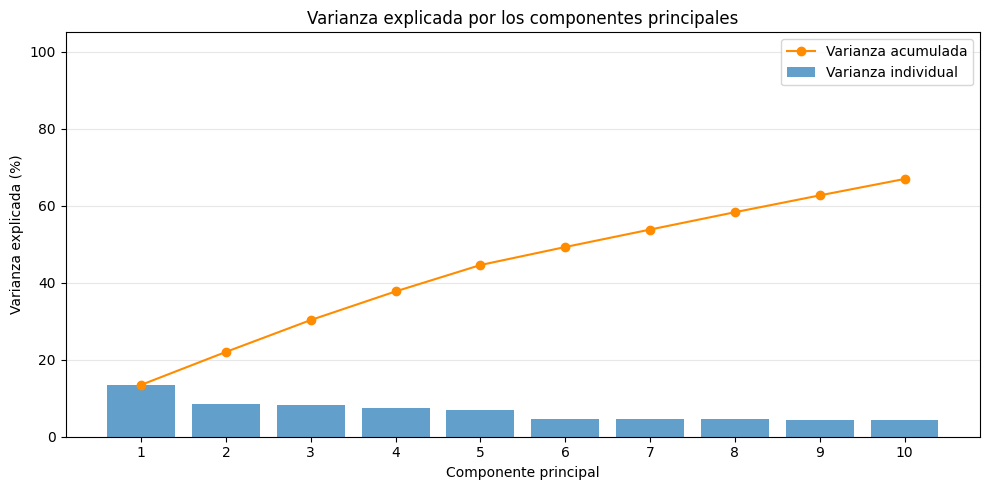

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))

componentes = np.arange(1, N_COMPONENTS + 1)

ax.bar(
    componentes,
    df_varianza["varianza_explicada_pct"],
    alpha=0.7,
    label="Varianza individual"
)

ax.plot(
    componentes,
    df_varianza["varianza_acumulada_pct"],
    marker="o",
    color="darkorange",
    label="Varianza acumulada"
)

ax.set_title("Varianza explicada por los componentes principales")
ax.set_xlabel("Componente principal")
ax.set_ylabel("Varianza explicada (%)")
ax.set_xticks(componentes)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
def varianza_explicada(k):
    return pca.explained_variance_ratio_[:k].sum() * 100


for k in [2, 5, 7, 10]:
    print(
        f"{k:2} componentes: "
        f"{varianza_explicada(k):.2f}% de varianza explicada"
    )

 2 componentes: 22.02% de varianza explicada
 5 componentes: 44.58% de varianza explicada
 7 componentes: 53.79% de varianza explicada
10 componentes: 66.92% de varianza explicada


### 4.5. Fundamento matemático de PCA mediante SVD
#### 4.5.1. Descomposición en valores singulares

In [36]:
# Centrar la matriz estandarizada
Z = X_train_scaled - X_train_scaled.mean(axis=0)

# Descomposición en valores singulares reducida
U, s, Vt = np.linalg.svd(
    Z,
    full_matrices=False
)

# Construcción de la matriz diagonal
Sigma = np.diag(s)

print(f"Dimensiones de Z:     {Z.shape}")
print(f"Dimensiones de U:     {U.shape}")
print(f"Dimensiones de Sigma: {Sigma.shape}")
print(f"Dimensiones de Vt:    {Vt.shape}")

Dimensiones de Z:     (1536, 24)
Dimensiones de U:     (1536, 24)
Dimensiones de Sigma: (24, 24)
Dimensiones de Vt:    (24, 24)


In [37]:
# Verificar la descomposición
Z_reconstruida = U @ Sigma @ Vt

print(
    "Reconstrucción correcta:",
    np.allclose(Z, Z_reconstruida)
)

Reconstrucción correcta: True


In [38]:
print("Columnas ortonormales de U:", np.allclose(U.T @ U, np.eye(U.shape[1])))

print("Columnas ortonormales de V:", np.allclose(Vt @ Vt.T, np.eye(Vt.shape[0])))

Columnas ortonormales de U: True
Columnas ortonormales de V: True


#### 4.5.2. Relación entre SVD y la matriz de covarianza

In [39]:
n = Z.shape[0]

valores_propios = s**2 / (n - 1)

df_svd = pd.DataFrame({
    "componente": [
        f"PC{i+1}" for i in range(len(s))
    ],
    "valor_singular": s,
    "valor_propio": valores_propios,
    "varianza_explicada_pct": (
        valores_propios / valores_propios.sum()
    ) * 100
})

display(df_svd.round(4))

,componente,valor_singular,valor_propio,varianza_explicada_pct
0,PC1,70.4520,3.2335,13.4643
1,PC2,56.1616,2.0548,8.5561
2,PC3,55.2398,1.9879,8.2776
3,PC4,52.3394,1.7846,7.4311
4,PC5,50.2551,1.6453,6.8511
5,PC6,41.5147,1.1228,4.6752
6,PC7,40.8692,1.0881,4.5310
7,PC8,40.7707,1.0829,4.5091
8,PC9,40.1196,1.0486,4.3663
9,PC10,39.6342,1.0234,4.2613


In [40]:
print(
    "Coincidencia de valores singulares:",
    np.allclose(
        s[:10],
        pca.singular_values_
    )
)

print(
    "Coincidencia de valores propios:",
    np.allclose(
        valores_propios[:10],
        pca.explained_variance_
    )
)

print(
    "Coincidencia de varianza explicada:",
    np.allclose(
        valores_propios[:10] / valores_propios.sum(),
        pca.explained_variance_ratio_
    )
)

Coincidencia de valores singulares: True
Coincidencia de valores propios: True
Coincidencia de varianza explicada: True


In [41]:
print(f"Suma de valores propios: {valores_propios.sum():.6f}")

Suma de valores propios: 24.015635


#### 4.5.3. Reducción dimensional y proyección mediante SVD

In [42]:
k = 10

U_k = U[:, :k]
Sigma_k = np.diag(s[:k])
V_k = Vt[:k, :].T

print(f"Dimensiones de U_k:     {U_k.shape}")
print(f"Dimensiones de Sigma_k: {Sigma_k.shape}")
print(f"Dimensiones de V_k:     {V_k.shape}")

Dimensiones de U_k:     (1536, 10)
Dimensiones de Sigma_k: (10, 10)
Dimensiones de V_k:     (24, 10)


In [43]:
# Proyección mediante los vectores singulares derechos
T_train_1 = Z @ V_k

# Proyección mediante los vectores singulares izquierdos
T_train_2 = U_k @ Sigma_k

print(f"Dimensiones de T_train_1: {T_train_1.shape}")
print(f"Dimensiones de T_train_2: {T_train_2.shape}")

print(
    "Equivalencia matemática:",
    np.allclose(T_train_1, T_train_2)
)

Dimensiones de T_train_1: (1536, 10)
Dimensiones de T_train_2: (1536, 10)
Equivalencia matemática: True


In [44]:
# Vectores singulares derechos utilizados por Scikit-learn
V_sklearn = pca.components_.T

# Identificar diferencias de signo
signos = np.sign(
    np.sum(V_k * V_sklearn, axis=0)
)

# Alinear los signos
V_k_alineado = V_k * signos

print(
    "Coincidencia de componentes principales:",
    np.allclose(V_k_alineado, V_sklearn)
)

Coincidencia de componentes principales: True


In [45]:
T_train_manual = Z @ V_k_alineado

print(
    "Coincidencia de proyección de entrenamiento:",
    np.allclose(T_train_manual, X_train_pca)
)

Coincidencia de proyección de entrenamiento: True


In [46]:
# Centrar los datos de prueba con la media de entrenamiento
Z_test_centrado = (
    X_test_scaled - X_train_scaled.mean(axis=0)
)

# Proyectar utilizando la base obtenida en entrenamiento
T_test_manual = Z_test_centrado @ V_k_alineado

print(f"Dimensiones originales: {X_test_scaled.shape}")
print(f"Dimensiones reducidas:  {T_test_manual.shape}")

print(
    "Coincidencia de proyección de prueba:",
    np.allclose(T_test_manual, X_test_pca)
)

Dimensiones originales: (385, 24)
Dimensiones reducidas:  (385, 10)
Coincidencia de proyección de prueba: True


In [47]:
print(
    "Base ortonormal:",
    np.allclose(
        V_k_alineado.T @ V_k_alineado,
        np.eye(k)
    )
)

Base ortonormal: True


---
## 5. Detección de fraude mediante la distancia de Mahalanobis
### 5.1. Preparación de los datos en dos dimensiones

In [48]:
# Máscaras booleanas
mask_legit = y_train.to_numpy() == 0
mask_fraud = y_train.to_numpy() == 1

# Separación de las transacciones de entrenamiento
X_train_legit = X_train_pca[mask_legit]
X_train_fraud = X_train_pca[mask_fraud]

print(f"Transacciones legítimas:    {X_train_legit.shape}")
print(f"Transacciones fraudulentas: {X_train_fraud.shape}")

Transacciones legítimas:    (1494, 10)
Transacciones fraudulentas: (42, 10)


In [49]:
k = 2 # Seleccionar los primeros dos componentes

X_legit_2d = X_train_legit[:, :k]
X_fraud_2d = X_train_fraud[:, :k]

print(f"X_legit_2d: {X_legit_2d.shape}")
print(f"X_fraud_2d: {X_fraud_2d.shape}")

print(f"Varianza explicada: {varianza_explicada(k):.4f}%")

X_legit_2d: (1494, 2)
X_fraud_2d: (42, 2)
Varianza explicada: 22.0204%


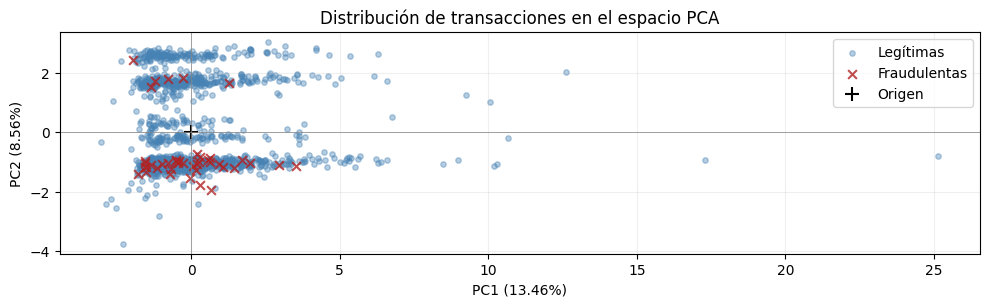

In [50]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    X_legit_2d[:, 0],
    X_legit_2d[:, 1],
    color="steelblue",
    alpha=0.4,
    s=15,
    label="Legítimas"
)

ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="firebrick",
    alpha=0.8,
    s=40,
    marker="x",
    label="Fraudulentas"
)

# Origen del espacio PCA
ax.scatter(
    0, 0,
    color="black",
    marker="+",
    s=100,
    label="Origen"
)

ax.set_title("Distribución de transacciones en el espacio PCA")
ax.set_xlabel(f"PC1 ({varianza_explicada(1):.2f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)

ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

- Solapamiento entre clases: una cantidad considerable de transacciones fraudulentas se encuentra dentro de regiones densamente pobladas por transacciones legítimas.
- Concentración del fraude: visualmente, la mayoría de las transacciones fraudulentas se concentra alrededor de PC2 = −1.
- Valores extremos legítimos: existen transacciones legítimas considerablemente alejadas del origen, particularmente sobre el eje PC1, donde una observación alcanza aproximadamente 25.
- Estructura no elíptica: las observaciones parecen distribuirse en bandas horizontales. Esto podría estar relacionado con la influencia de las variables binarias originales sobre los componentes principales, aunque todavía no lo hemos comprobado.

#### 5.2. Construcción de la matriz de covarianza

In [51]:
# Media de las transacciones legítimas
mu_legit_2d = X_legit_2d.mean(axis=0)

# Matriz de covarianza muestral
Sigma_2d = np.cov(X_legit_2d,rowvar=False, ddof=1)

print("Vector de medias:")
print(mu_legit_2d)

print("\nMatriz de covarianza:")
print(Sigma_2d)

print(f"\nDimensiones: {Sigma_2d.shape}")

Vector de medias:
[0.00270276 0.01997564]

Matriz de covarianza:
[[3.28077337 0.00536361]
 [0.00536361 2.06622386]]

Dimensiones: (2, 2)


In [ ]:
# Propiedades algebraicas
es_simetrica = np.allclose(Sigma_2d, Sigma_2d.T) # Permite una descomposición espectral, es decir, puede ser diagonalizada por una matriz ortogonal
rango = np.linalg.matrix_rank(Sigma_2d)
determinante = np.linalg.det(Sigma_2d)
valores_propios_maha, vectores_propios_maha = (np.linalg.eigh(Sigma_2d))
es_definida_positiva = np.all(valores_propios_maha > 0)
numero_condicion = np.linalg.cond(Sigma_2d) # Evalía la estabilidad numérica de la matriz, valores grandes indican problemas de estabilidad

print(f"Es simétrica: {es_simetrica}")
print(f"Rango: {rango}")
print(f"Determinante: {determinante:.6f}")
print(f"Valores propios: {valores_propios_maha}")
print(f"Es definida positiva: {es_definida_positiva}")
print(f"Número de condición: {numero_condicion:.6f}")

Es simétrica: True
Rango: 2
Determinante: 6.778783
Valores propios: [2.06620017 3.28079705]
Es definida positiva: True
Número de condición: 1.587841


#### 5.2.1. Interpretación geométria de la matriz de covarianza

In [54]:
Q = vectores_propios_maha
Lambda = np.diag(valores_propios_maha)

Sigma_reconstruida = Q @ Lambda @ Q.T

print(
    "Reconstrucción espectral:",
    np.allclose(Sigma_2d, Sigma_reconstruida)
)

print(
    "Base ortonormal:",
    np.allclose(Q.T @ Q, np.eye(2))
)

Reconstrucción espectral: True
Base ortonormal: True


#### 5.3. Implementación de la distancia de Mahalanobis

In [55]:
# Inversa de la matriz de covarianza
Sigma_inv_2d = np.linalg.inv(Sigma_2d)

print("Matriz de covarianza inversa:")
print(Sigma_inv_2d)

print(
    "\nValidación de la matriz inversa:",
    np.allclose(
        Sigma_2d @ Sigma_inv_2d,
        np.eye(2)
    )
)

Matriz de covarianza inversa:
[[ 0.30480747 -0.00079123]
 [-0.00079123  0.48397672]]

Validación de la matriz inversa: True


In [56]:
def distancia_mahalanobis_individual(x, Sigma_inv):
    return np.sqrt(x.T @ Sigma_inv @ x)

In [57]:
# Prueba de la función con un vector de ejemplo
x = X_legit_2d[0]

distancia = distancia_mahalanobis_individual(
    x,
    Sigma_inv_2d
)

print(f"Transacción: {x}")
print(f"Distancia de Mahalanobis: {distancia:.6f}")

Transacción: [-0.70483785 -0.90982363]
Distancia de Mahalanobis: 0.742319


In [58]:
def distancia_mahalanobis(X, Sigma):
    X = np.atleast_2d(X)

    # Resolver Sigma @ W.T = X.T
    W = np.linalg.solve(Sigma, X.T).T

    # Calcular la forma cuadrática por observación
    distancias_cuadradas = np.sum(X * W, axis=1)

    # Evitar valores negativos por redondeo numérico
    return np.sqrt(np.maximum(distancias_cuadradas, 0))

In [59]:
distancia_vectorizada = distancia_mahalanobis(
    X_legit_2d[:1],
    Sigma_2d
)[0]

print(
    "Coincidencia entre implementaciones:",
    np.isclose(distancia, distancia_vectorizada)
)

Coincidencia entre implementaciones: True


In [60]:
distancias_legit_2d = distancia_mahalanobis(
    X_legit_2d,
    Sigma_2d
)

distancias_fraud_2d = distancia_mahalanobis(
    X_fraud_2d,
    Sigma_2d
)

print(f"Distancias legítimas: {distancias_legit_2d.shape}")
print(f"Distancias fraudulentas: {distancias_fraud_2d.shape}")

Distancias legítimas: (1494,)
Distancias fraudulentas: (42,)


In [61]:
df_distancias_2d = pd.DataFrame({
    "Legítimas": pd.Series(distancias_legit_2d),
    "Fraudulentas": pd.Series(distancias_fraud_2d)
})

display(df_distancias_2d.describe().round(4))

,Legítimas,Fraudulentas
count,1494.0000,42.0000
mean,1.2035,1.0697
std,0.7421,0.3519
min,0.1039,0.5218
25%,0.8241,0.7703
50%,1.0235,1.0619
75%,1.3805,1.2748
max,13.8939,2.0943


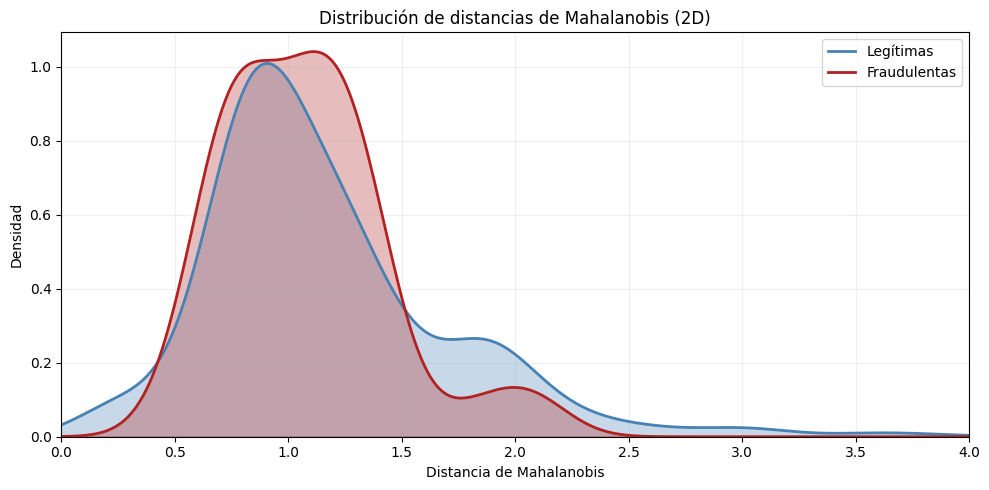

In [64]:
from scipy.stats import gaussian_kde

# Estimación de densidad para cada clase
kde_legit = gaussian_kde(distancias_legit_2d)
kde_fraud = gaussian_kde(distancias_fraud_2d)

# Dominio de evaluación
x = np.linspace(
    0,
    max(distancias_legit_2d.max(), distancias_fraud_2d.max()),
    1000
)

# Evaluación de las funciones de densidad
densidad_legit = kde_legit(x)
densidad_fraud = kde_fraud(x)

# Visualización
fig, ax = plt.subplots(figsize=(10, 5))

# Transacciones legítimas
ax.plot(
    x, densidad_legit,
    color="steelblue",
    linewidth=2,
    label="Legítimas"
)

ax.fill_between(
    x, densidad_legit,
    color="steelblue",
    alpha=0.3
)

# Transacciones fraudulentas
ax.plot(
    x, densidad_fraud,
    color="firebrick",
    linewidth=2,
    label="Fraudulentas"
)

ax.fill_between(
    x, densidad_fraud,
    color="firebrick",
    alpha=0.3
)

ax.set_title("Distribución de distancias de Mahalanobis (2D)")
ax.set_xlabel("Distancia de Mahalanobis")
ax.set_ylabel("Densidad")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.2)
ax.set_xlim(0,4)

plt.tight_layout()
plt.show()

Las transacciones fraudulentas no presentan sistemáticamente distancias mayores que las legítimas. De hecho, las transacciones legítimas presentan una media superior y una cola derecha considerablemente más extensa.

#### 5.4. Construcción de radios mediante percentiles empíricos

In [65]:
# Determinar el número de observaciones necesarias para cada percentil
PERCENTILES = [50, 75, 90, 95, 99]

N = len(distancias_legit_2d)

df_objetivos = pd.DataFrame({
    "percentil": PERCENTILES,
    "observaciones_minimas": [
        int(np.ceil(p * N / 100))
        for p in PERCENTILES
    ]
})

display(df_objetivos)

,percentil,observaciones_minimas
0,50,747
1,75,1121
2,90,1345
3,95,1420
4,99,1480


In [66]:
# Calcular los radios de Mahalanobis para los percentiles especificados
def calcular_radios(scores, percentiles=PERCENTILES):
    scores_ordenados = np.sort(scores)
    N = len(scores_ordenados)

    radios = {}

    for p in percentiles:
        m = int(np.ceil(p * N / 100))

        # Python comienza a indexar desde cero
        radios[p] = scores_ordenados[m - 1]

    return radios

In [67]:
radios_maha_2d = calcular_radios(distancias_legit_2d)

for p, radio in radios_maha_2d.items():
    print(f"Radio {p}%: {radio:.6f}")

Radio 50%: 1.022705
Radio 75%: 1.380520
Radio 90%: 1.921903
Radio 95%: 2.175282
Radio 99%: 3.637514


In [ ]:
# Cobertura de las regiones
resultados_cobertura = []

for p, radio in radios_maha_2d.items():

    dentro = np.sum(distancias_legit_2d <= radio)
    fuera = np.sum(distancias_legit_2d > radio)

    cobertura = dentro / N * 100

    resultados_cobertura.append({
        "percentil": p,
        "radio": radio,
        "legitimas_dentro": dentro,
        "legitimas_fuera": fuera,
        "cobertura_pct": cobertura,
        "cumple_condicion": p <= cobertura < p + 1
    })

df_cobertura_maha_2d = pd.DataFrame(
    resultados_cobertura
)

display(df_cobertura_maha_2d.round(4))

,percentil,radio,legitimas_dentro,legitimas_fuera,cobertura_pct,cumple_condicion
0,50,1.0227,747,747,50.0000,True
1,75,1.3805,1121,373,75.0335,True
2,90,1.9219,1345,149,90.0268,True
3,95,2.1753,1420,74,95.0469,True
4,99,3.6375,1480,14,99.0629,True


In [ ]:
# Cobertura de las regiones para transacciones fraudulentas
resultados_fraude = []

N_fraud = len(distancias_fraud_2d)

for p, radio in radios_maha_2d.items():

    dentro = np.sum(distancias_fraud_2d <= radio)
    fuera = np.sum(distancias_fraud_2d > radio)

    resultados_fraude.append({
        "percentil": p,
        "radio": radio,
        "fraudes_dentro": dentro,
        "fraudes_fuera": fuera,
        "fraudes_dentro_pct": dentro / N_fraud * 100,
        "fraudes_fuera_pct": fuera / N_fraud * 100
    })

df_cobertura_fraud_2d = pd.DataFrame(
    resultados_fraude
)

display(df_cobertura_fraud_2d.round(4))

,percentil,radio,fraudes_dentro,fraudes_fuera,fraudes_dentro_pct,fraudes_fuera_pct
0,50,1.0227,19,23,45.2381,54.7619
1,75,1.3805,37,5,88.0952,11.9048
2,90,1.9219,40,2,95.2381,4.7619
3,95,2.1753,42,0,100.0000,0.0000
4,99,3.6375,42,0,100.0000,0.0000


#### 5.5. Visualización de las elipses de Mahalanobis

In [71]:
def generar_elipse_mahalanobis(
    Sigma,
    radio,
    n_puntos=360
):
    # Descomposición espectral
    valores, vectores = np.linalg.eigh(Sigma)

    # Parametrización de la circunferencia unitaria
    theta = np.linspace(0, 2 * np.pi, n_puntos)

    circulo = np.array([
        np.cos(theta),
        np.sin(theta)
    ])

    # Escalamiento mediante los valores propios
    Lambda_sqrt = np.diag(np.sqrt(valores))

    # Transformación de la circunferencia en elipse
    elipse = radio * vectores @ Lambda_sqrt @ circulo

    return elipse.T

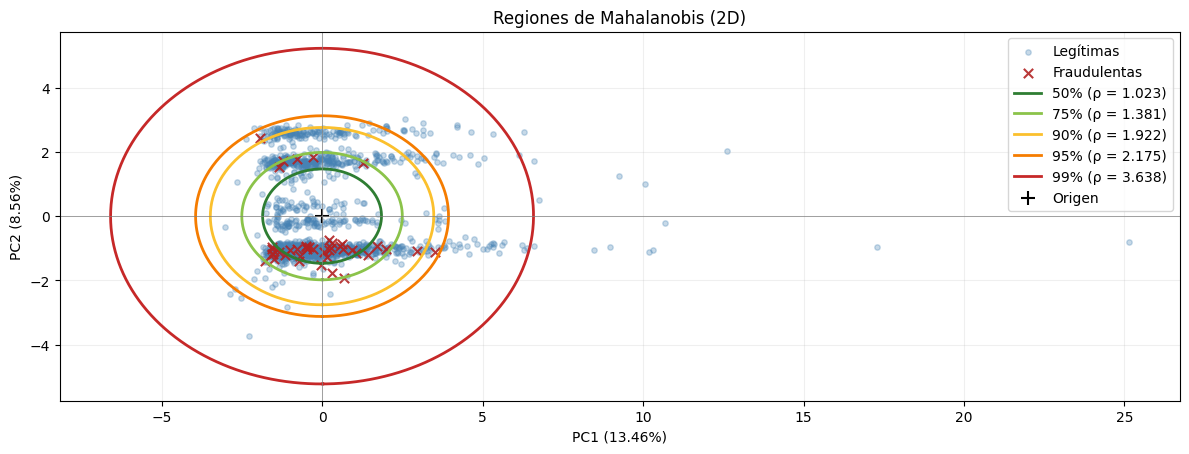

In [73]:
colores_percentiles = {
    50: "#2E7D32",
    75: "#8BC34A",
    90: "#FBC02D",
    95: "#F57C00",
    99: "#C62828"
}

fig, ax = plt.subplots(figsize=(12, 8))

# Transacciones legítimas
ax.scatter(
    X_legit_2d[:, 0],
    X_legit_2d[:, 1],
    color="steelblue",
    alpha=0.3,
    s=15,
    label="Legítimas"
)

# Transacciones fraudulentas
ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="firebrick",
    alpha=0.9,
    s=45,
    marker="x",
    label="Fraudulentas"
)

# Fronteras de Mahalanobis
for p, radio in radios_maha_2d.items():

    elipse = generar_elipse_mahalanobis(
        Sigma_2d,
        radio
    )

    ax.plot(
        elipse[:, 0],
        elipse[:, 1],
        color=colores_percentiles[p],
        linewidth=2,
        label=f"{p}% (ρ = {radio:.3f})"
    )

# Origen
ax.scatter(
    0, 0,
    color="black",
    marker="+",
    s=100,
    label="Origen"
)

# Configuración de la gráfica
ax.set_title("Regiones de Mahalanobis (2D)")
ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)"
)

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)

ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

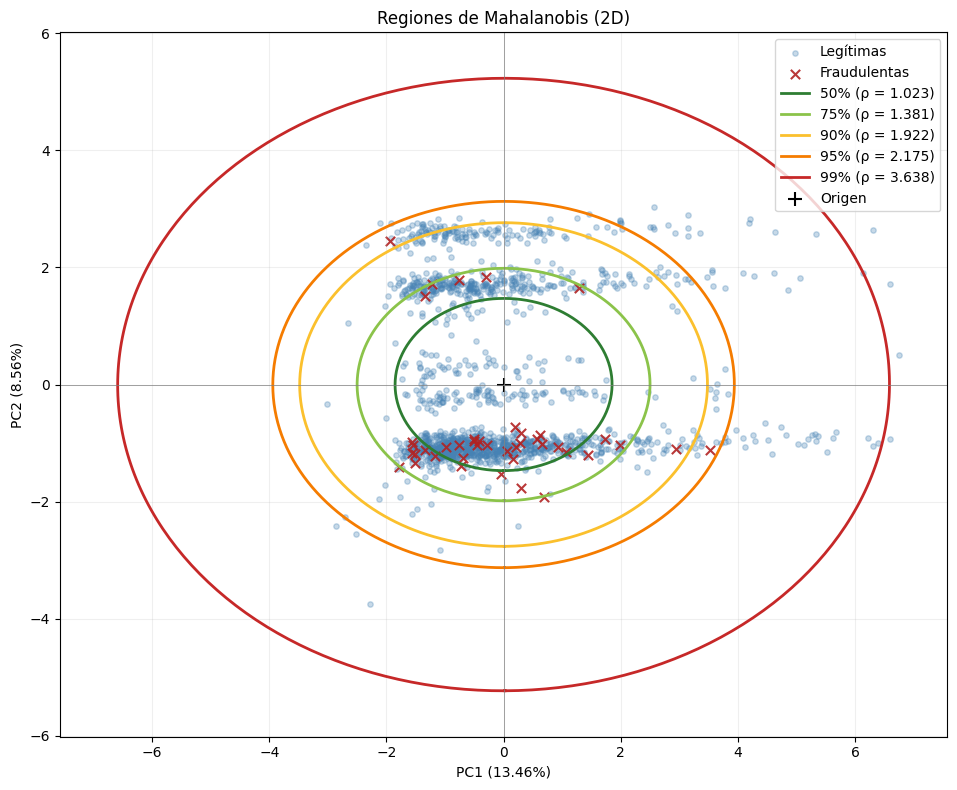

In [75]:
colores_percentiles = {
    50: "#2E7D32",
    75: "#8BC34A",
    90: "#FBC02D",
    95: "#F57C00",
    99: "#C62828"
}

fig, ax = plt.subplots(figsize=(12, 8))

# Transacciones legítimas
ax.scatter(
    X_legit_2d[:, 0],
    X_legit_2d[:, 1],
    color="steelblue",
    alpha=0.3,
    s=15,
    label="Legítimas"
)

# Transacciones fraudulentas
ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="firebrick",
    alpha=0.9,
    s=45,
    marker="x",
    label="Fraudulentas"
)

# Fronteras de Mahalanobis
for p, radio in radios_maha_2d.items():

    elipse = generar_elipse_mahalanobis(
        Sigma_2d,
        radio
    )

    ax.plot(
        elipse[:, 0],
        elipse[:, 1],
        color=colores_percentiles[p],
        linewidth=2,
        label=f"{p}% (ρ = {radio:.3f})"
    )

# Origen
ax.scatter(
    0, 0,
    color="black",
    marker="+",
    s=100,
    label="Origen"
)

# Configuración de la gráfica
ax.set_title("Regiones de Mahalanobis (2D)")
ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)"
)

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)

ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right")
ax.grid(alpha=0.2)

# Acercamiento basado en la elipse del 99%
elipse_99 = generar_elipse_mahalanobis(
    Sigma_2d,
    radios_maha_2d[99]
)

limite_x = np.abs(elipse_99[:, 0]).max() * 1.15
limite_y = np.abs(elipse_99[:, 1]).max() * 1.15

ax.set_xlim(-limite_x, limite_x)
ax.set_ylim(-limite_y, limite_y)

plt.tight_layout()
plt.show()


In [ ]:
# Calcular las dimensiones de las elipses
resultados_elipses = []

for p, radio in radios_maha_2d.items():

    semiejes = radio * np.sqrt(valores_propios_maha)

    area = np.pi * np.prod(semiejes)

    resultados_elipses.append({
        "percentil": p,
        "radio": radio,
        "semieje_menor": semiejes.min(),
        "semieje_mayor": semiejes.max(),
        "area": area
    })

df_elipses_maha_2d = pd.DataFrame(
    resultados_elipses
)

display(df_elipses_maha_2d.round(4))

,percentil,radio,semieje_menor,semieje_mayor,area
0,50,1.0227,1.4701,1.8524,8.5551
1,75,1.3805,1.9844,2.5005,15.5887
2,90,1.9219,2.7626,3.4811,30.2126
3,95,2.1753,3.1268,3.9401,38.7041
4,99,3.6375,5.2287,6.5886,108.2269


Una transacción alejada del origen no necesariamente tiene una mayor probabilidad de ser fraudulenta. Esta es una limitación de Mahalanobis.

#### 5.6. Determinación de las regiones de seguridad y peligro

In [77]:
def asignar_regiones(scores, radios):

    limites = np.array([
        radios[p] for p in sorted(radios)
    ])

    regiones = np.searchsorted(
        limites,
        scores,
        side="left"
    )

    return regiones + 1

In [78]:
regiones_legit_2d = asignar_regiones(
    distancias_legit_2d,
    radios_maha_2d
)

regiones_fraud_2d = asignar_regiones(
    distancias_fraud_2d,
    radios_maha_2d
)

print(f"Legítimas: {regiones_legit_2d.shape}")
print(f"Fraudulentas: {regiones_fraud_2d.shape}")

Legítimas: (1494,)
Fraudulentas: (42,)


In [79]:
# Calcular el riesgo empírico para cada región de Mahalanobis
nombres_regiones = {
    1: "0% - 50%",
    2: "50% - 75%",
    3: "75% - 90%",
    4: "90% - 95%",
    5: "95% - 99%",
    6: "Exterior 99%"
}

resultados_regiones = []

for i, nombre in nombres_regiones.items():

    n_legit = np.sum(regiones_legit_2d == i)
    n_fraud = np.sum(regiones_fraud_2d == i)

    total = n_legit + n_fraud

    riesgo = n_fraud / total if total > 0 else np.nan

    resultados_regiones.append({
        "region": i,
        "intervalo": nombre,
        "legitimas": n_legit,
        "fraudulentas": n_fraud,
        "total": total,
        "riesgo_pct": riesgo * 100
    })

df_regiones_maha_2d = pd.DataFrame(
    resultados_regiones
)

display(df_regiones_maha_2d.round(4))

,region,intervalo,legitimas,fraudulentas,total,riesgo_pct
0,1,0% - 50%,747,19,766,2.4804
1,2,50% - 75%,374,18,392,4.5918
2,3,75% - 90%,224,3,227,1.3216
3,4,90% - 95%,75,2,77,2.5974
4,5,95% - 99%,60,0,60,0.0000
5,6,Exterior 99%,14,0,14,0.0000


In [80]:
# Comparar con el riesgo global
riesgo_global = y_train.mean() * 100

df_regiones_maha_2d["riesgo_relativo"] = (
    df_regiones_maha_2d["riesgo_pct"] / riesgo_global
)

print(f"Riesgo global: {riesgo_global:.4f}%")

display(df_regiones_maha_2d.round(4))

Riesgo global: 2.7344%


,region,intervalo,legitimas,fraudulentas,total,riesgo_pct,riesgo_relativo
0,1,0% - 50%,747,19,766,2.4804,0.9071
1,2,50% - 75%,374,18,392,4.5918,1.6793
2,3,75% - 90%,224,3,227,1.3216,0.4833
3,4,90% - 95%,75,2,77,2.5974,0.9499
4,5,95% - 99%,60,0,60,0.0000,0.0000
5,6,Exterior 99%,14,0,14,0.0000,0.0000


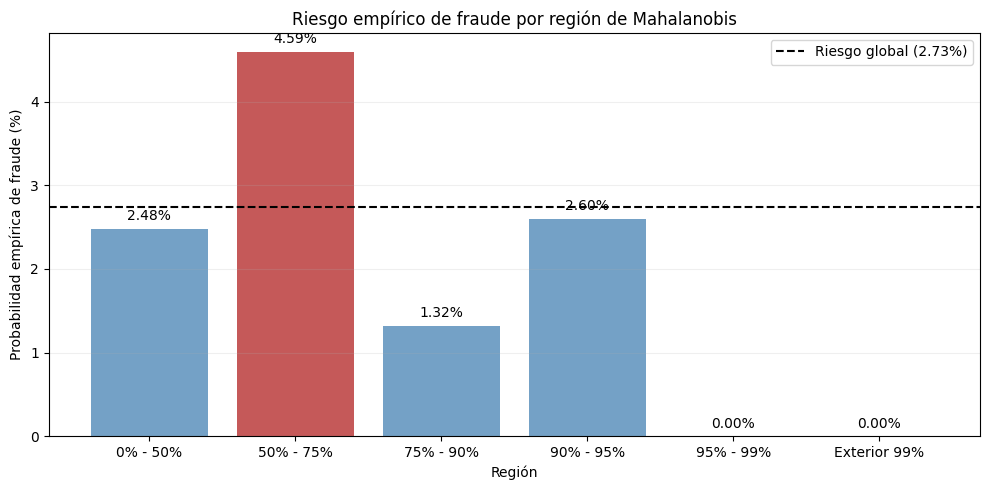

In [81]:
fig, ax = plt.subplots(figsize=(10, 5))

colores = np.where(
    df_regiones_maha_2d["riesgo_pct"] > riesgo_global,
    "firebrick",
    "steelblue"
)

barras = ax.bar(
    df_regiones_maha_2d["intervalo"],
    df_regiones_maha_2d["riesgo_pct"],
    color=colores,
    alpha=0.75
)

ax.axhline(
    riesgo_global,
    color="black",
    linestyle="--",
    label=f"Riesgo global ({riesgo_global:.2f}%)"
)

ax.bar_label(
    barras,
    fmt="%.2f%%",
    padding=4
)

ax.set_title("Riesgo empírico de fraude por región de Mahalanobis")
ax.set_xlabel("Región")
ax.set_ylabel("Probabilidad empírica de fraude (%)")
ax.set_ylim(bottom=0)
ax.margins(y=0.15)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

El riesgo de fraude no aumenta conforme aumenta la distancia de Mahalanobis en dos dimensiones

#### 5.7. Calibración del umbral de detección

In [82]:
def evaluar_umbral(y_real, scores, umbral):

    # Regla de clasificación
    y_pred = (scores > umbral).astype(int)

    # Matriz de confusión
    tn, fp, fn, tp = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "fpr": fp / (fp + tn),
        "specificity": tn / (tn + fp),
        "balanced_accuracy": balanced_accuracy_score(
            y_real, y_pred
        )
    }

In [83]:
scores_train_maha_2d = distancia_mahalanobis(
    X_train_pca[:, :2],
    Sigma_2d
)

resultados_umbral = []

for p, radio in radios_maha_2d.items():

    metricas = evaluar_umbral(
        y_train,
        scores_train_maha_2d,
        radio
    )

    resultados_umbral.append({
        "percentil": p,
        "radio": radio,
        **metricas
    })

df_evaluacion_maha_2d = pd.DataFrame(
    resultados_umbral
)

display(df_evaluacion_maha_2d.round(4))

,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,50,1.0227,747,747,19,23,0.0299,0.5476,0.0567,0.5000,0.5000,0.5238
1,75,1.3805,1121,373,37,5,0.0132,0.1190,0.0238,0.2497,0.7503,0.4347
2,90,1.9219,1345,149,40,2,0.0132,0.0476,0.0207,0.0997,0.9003,0.4739
3,95,2.1753,1420,74,42,0,0.0000,0.0000,0.0000,0.0495,0.9505,0.4752
4,99,3.6375,1480,14,42,0,0.0000,0.0000,0.0000,0.0094,0.9906,0.4953


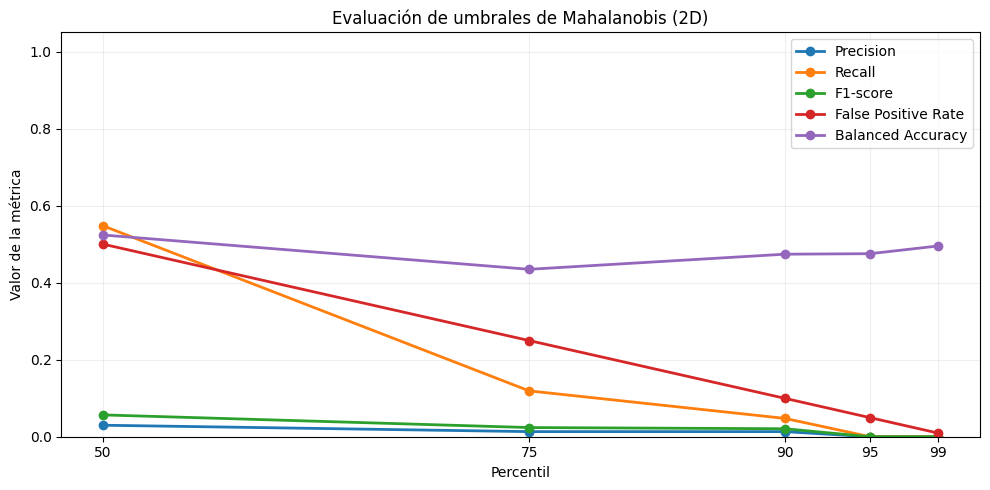

In [84]:
fig, ax = plt.subplots(figsize=(10, 5))

metricas = {
    "precision": "Precision",
    "recall": "Recall",
    "f1_score": "F1-score",
    "fpr": "False Positive Rate",
    "balanced_accuracy": "Balanced Accuracy"
}

for columna, nombre in metricas.items():

    ax.plot(
        df_evaluacion_maha_2d["percentil"],
        df_evaluacion_maha_2d[columna],
        marker="o",
        linewidth=2,
        label=nombre
    )

ax.set_title("Evaluación de umbrales de Mahalanobis (2D)")
ax.set_xlabel("Percentil")
ax.set_ylabel("Valor de la métrica")
ax.set_xticks(PERCENTILES)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [85]:
def seleccionar_umbral(df_evaluacion):

    return df_evaluacion.sort_values(
        by=["f1_score", "recall", "fpr"],
        ascending=[False, False, True]
    ).iloc[0]


mejor_maha_2d = seleccionar_umbral(
    df_evaluacion_maha_2d
)

umbral_maha_2d = mejor_maha_2d["radio"]

print(
    f"Percentil seleccionado: "
    f"{mejor_maha_2d['percentil']:.0f}%"
)

print(f"Radio seleccionado: {umbral_maha_2d:.6f}")
print(f"Precision: {mejor_maha_2d['precision']:.4f}")
print(f"Recall: {mejor_maha_2d['recall']:.4f}")
print(f"F1-score: {mejor_maha_2d['f1_score']:.4f}")
print(f"FPR: {mejor_maha_2d['fpr']:.4f}")

Percentil seleccionado: 50%
Radio seleccionado: 1.022705
Precision: 0.0299
Recall: 0.5476
F1-score: 0.0567
FPR: 0.5000


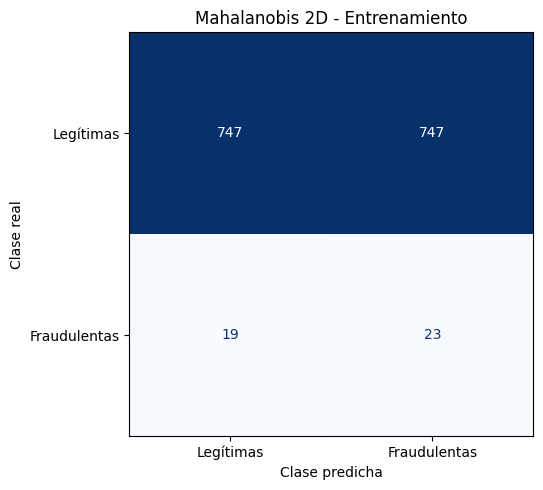

In [86]:
from sklearn.metrics import ConfusionMatrixDisplay

y_pred_train_maha_2d = (
    scores_train_maha_2d > umbral_maha_2d
).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_train_maha_2d,
    labels=[0, 1],
    display_labels=["Legítimas", "Fraudulentas"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Mahalanobis 2D - Entrenamiento")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

#### 5.8. Evaluación sobre el conjunto de prueba

In [87]:
from time import perf_counter

# Seleccionar los primeros dos componentes
X_test_2d = X_test_pca[:, :2]

# Inicio de inferencia
inicio = perf_counter()

scores_test_maha_2d = distancia_mahalanobis(
    X_test_2d,
    Sigma_2d
)

# Clasificación con el umbral de entrenamiento
y_pred_test_maha_2d = (
    scores_test_maha_2d > umbral_maha_2d
).astype(int)

# Fin de inferencia
tiempo_inferencia_maha_2d = perf_counter() - inicio

print(f"Dimensiones de prueba: {X_test_2d.shape}")
print(f"Distancias calculadas: {scores_test_maha_2d.shape}")
print(f"Predicciones: {y_pred_test_maha_2d.shape}")

print(
    f"Tiempo de inferencia: "
    f"{tiempo_inferencia_maha_2d:.6f} segundos"
)

Dimensiones de prueba: (385, 2)
Distancias calculadas: (385,)
Predicciones: (385,)
Tiempo de inferencia: 0.000412 segundos


In [ ]:
# Evaluación de desempeño en el conjunto de prueba
metricas_test_maha_2d = evaluar_umbral(
    y_test,
    scores_test_maha_2d,
    umbral_maha_2d
)

df_test_maha_2d = pd.DataFrame([{
    "metodo": "Mahalanobis",
    "componentes": 2,
    "varianza_explicada_pct": (
        pca.explained_variance_ratio_[:2].sum() * 100
    ),
    "percentil": mejor_maha_2d["percentil"],
    "radio": umbral_maha_2d,
    "tiempo_inferencia_s": tiempo_inferencia_maha_2d,
    **metricas_test_maha_2d
}])

display(df_test_maha_2d.round(6))

,metodo,componentes,varianza_explicada_pct,percentil,radio,tiempo_inferencia_s,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,Mahalanobis,2,22.020426,50.0,1.022705,0.000412,174,201,6,4,0.019512,0.4,0.037209,0.536,0.464,0.432


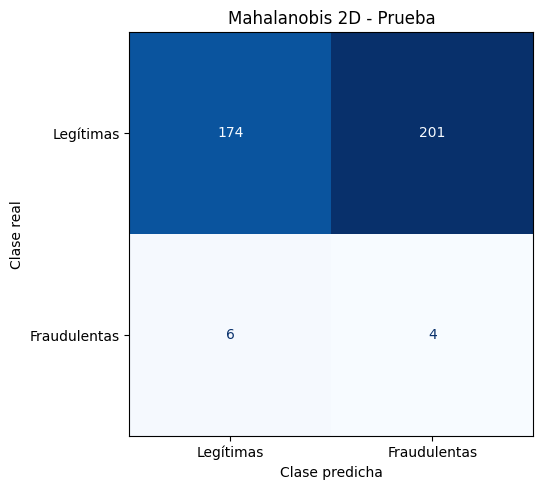

In [89]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test_maha_2d,
    labels=[0, 1],
    display_labels=["Legítimas", "Fraudulentas"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Mahalanobis 2D - Prueba")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

In [90]:
columnas_metricas = [
    "precision",
    "recall",
    "f1_score",
    "fpr",
    "specificity",
    "balanced_accuracy"
]

df_comparacion_maha_2d = pd.DataFrame({
    "Entrenamiento": mejor_maha_2d[columnas_metricas],
    "Prueba": pd.Series(metricas_test_maha_2d)[columnas_metricas]
}).astype(float)

df_comparacion_maha_2d["Diferencia"] = (
    df_comparacion_maha_2d["Prueba"]
    - df_comparacion_maha_2d["Entrenamiento"]
)

display(df_comparacion_maha_2d.round(4))

,Entrenamiento,Prueba,Diferencia
precision,0.0299,0.0195,-0.0104
recall,0.5476,0.4000,-0.1476
f1_score,0.0567,0.0372,-0.0194
fpr,0.5000,0.5360,0.0360
specificity,0.5000,0.4640,-0.0360
balanced_accuracy,0.5238,0.4320,-0.0918


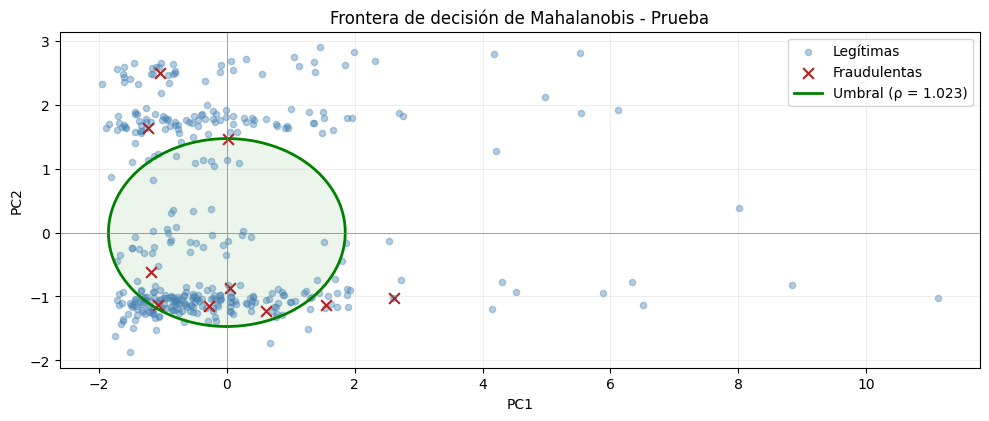

In [91]:
mask_test_legit = np.asarray(y_test) == 0
mask_test_fraud = np.asarray(y_test) == 1

X_test_legit_2d = X_test_2d[mask_test_legit]
X_test_fraud_2d = X_test_2d[mask_test_fraud]

elipse_umbral = generar_elipse_mahalanobis(
    Sigma_2d,
    umbral_maha_2d
)

fig, ax = plt.subplots(figsize=(10, 7))

# Región clasificada como legítima
ax.fill(
    elipse_umbral[:, 0],
    elipse_umbral[:, 1],
    color="green",
    alpha=0.08
)

# Transacciones legítimas
ax.scatter(
    X_test_legit_2d[:, 0],
    X_test_legit_2d[:, 1],
    color="steelblue",
    alpha=0.4,
    s=20,
    label="Legítimas"
)

# Transacciones fraudulentas
ax.scatter(
    X_test_fraud_2d[:, 0],
    X_test_fraud_2d[:, 1],
    color="firebrick",
    marker="x",
    s=60,
    label="Fraudulentas"
)

# Frontera de decisión
ax.plot(
    elipse_umbral[:, 0],
    elipse_umbral[:, 1],
    color="green",
    linewidth=2,
    label=f"Umbral (ρ = {umbral_maha_2d:.3f})"
)

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)

ax.set_title("Frontera de decisión de Mahalanobis - Prueba")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### 5.9. Generalización de Mahalanobis a 10 dimensiones

In [92]:
k = 10

X_legit_10d = X_train_legit[:, :k]
X_fraud_10d = X_train_fraud[:, :k]
X_test_10d = X_test_pca[:, :k]

varianza_10d = (
    pca.explained_variance_ratio_[:k].sum() * 100
)

print(f"Legítimas: {X_legit_10d.shape}")
print(f"Fraudulentas: {X_fraud_10d.shape}")
print(f"Prueba: {X_test_10d.shape}")
print(f"Varianza explicada: {varianza_10d:.4f}%")

Legítimas: (1494, 10)
Fraudulentas: (42, 10)
Prueba: (385, 10)
Varianza explicada: 66.9230%


In [93]:
# Construir y validar la matriz de covarianza
Sigma_10d = np.cov(
    X_legit_10d,
    rowvar=False,
    ddof=1
)

valores_propios_10d = np.linalg.eigvalsh(Sigma_10d)

print(f"Dimensiones: {Sigma_10d.shape}")

print(
    "Es simétrica:",
    np.allclose(Sigma_10d, Sigma_10d.T)
)

print(f"Rango: {np.linalg.matrix_rank(Sigma_10d)}")

print(
    f"Determinante: "
    f"{np.linalg.det(Sigma_10d):.6f}"
)

print(f"Valores propios:\n{valores_propios_10d}")

print(
    "Es definida positiva:",
    np.all(valores_propios_10d > 0)
)

print(
    f"Número de condición: "
    f"{np.linalg.cond(Sigma_10d):.6f}"
)

assert np.all(valores_propios_10d > 0), (
    "La matriz no es definida positiva."
)

Dimensiones: (10, 10)
Es simétrica: True
Rango: 10
Determinante: 54.864811
Valores propios:
[0.99994256 1.04567206 1.07889519 1.08913481 1.11900365 1.64108818
 1.80560623 1.98621411 2.06655479 3.28097542]
Es definida positiva: True
Número de condición: 3.281164


In [94]:
# Distancias de entrenamiento
distancias_legit_10d = distancia_mahalanobis(
    X_legit_10d,
    Sigma_10d
)

distancias_fraud_10d = distancia_mahalanobis(
    X_fraud_10d,
    Sigma_10d
)

scores_train_maha_10d = distancia_mahalanobis(
    X_train_pca[:, :10],
    Sigma_10d
)

df_distancias_10d = pd.DataFrame({
    "Legítimas": pd.Series(distancias_legit_10d),
    "Fraudulentas": pd.Series(distancias_fraud_10d)
})

display(df_distancias_10d.describe().round(4))

,Legítimas,Fraudulentas
count,1494.0000,42.0000
mean,2.9515,3.0496
std,1.1328,0.9373
min,0.8830,1.4890
25%,2.2721,2.5155
50%,2.7282,2.9220
75%,3.3895,3.6337
max,16.3707,5.3918


In [95]:
# Comparar las distribuciones de densidad
def graficar_densidades(
    scores_legit,
    scores_fraud,
    titulo,
    limite_x=None
):
    kde_legit = gaussian_kde(scores_legit)
    kde_fraud = gaussian_kde(scores_fraud)

    x = np.linspace(
        0,
        max(scores_legit.max(), scores_fraud.max()),
        1000
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    for kde, color, nombre in [
        (kde_legit, "steelblue", "Legítimas"),
        (kde_fraud, "firebrick", "Fraudulentas")
    ]:
        densidad = kde(x)

        ax.plot(
            x, densidad,
            color=color,
            linewidth=2,
            label=nombre
        )

        ax.fill_between(
            x, densidad,
            color=color,
            alpha=0.3
        )

    ax.set_title(titulo)
    ax.set_xlabel("Puntuación de anomalía")
    ax.set_ylabel("Densidad")

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    if limite_x is not None:
        ax.set_xlim(0, limite_x)

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

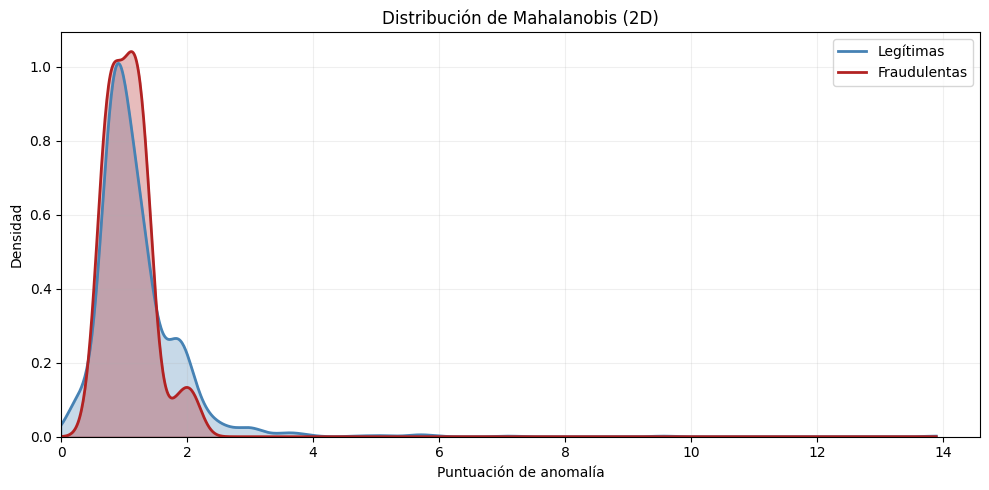

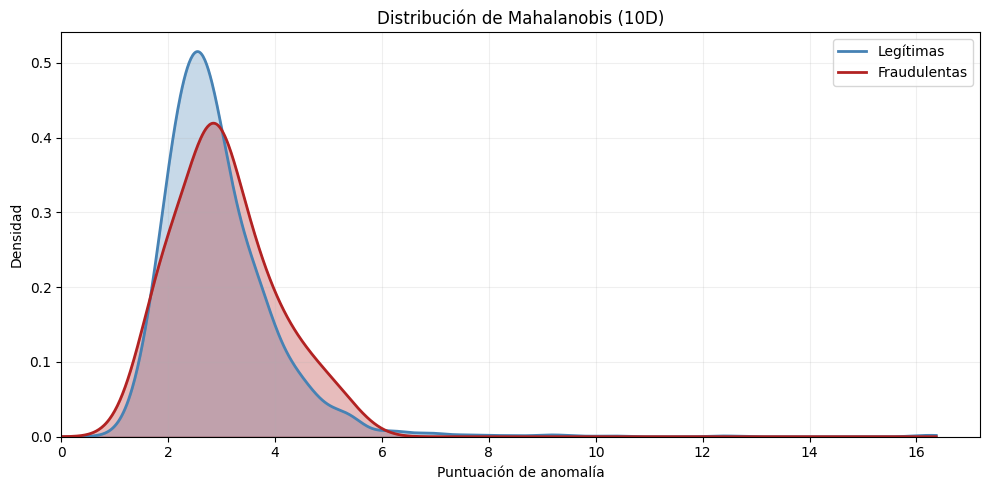

In [96]:
graficar_densidades(
    distancias_legit_2d,
    distancias_fraud_2d,
    "Distribución de Mahalanobis (2D)"
)

graficar_densidades(
    distancias_legit_10d,
    distancias_fraud_10d,
    "Distribución de Mahalanobis (10D)"
)

In [97]:
# Radios empíricos
radios_maha_10d = calcular_radios(
    distancias_legit_10d
)

resultados_cobertura_10d = []

for p, radio in radios_maha_10d.items():

    cobertura = (
        np.mean(distancias_legit_10d <= radio) * 100
    )

    resultados_cobertura_10d.append({
        "percentil": p,
        "radio": radio,
        "cobertura_legit_pct": cobertura,
        "cumple_condicion": p <= cobertura < p + 1,
        "fraudes_dentro": np.sum(
            distancias_fraud_10d <= radio
        ),
        "fraudes_fuera": np.sum(
            distancias_fraud_10d > radio
        )
    })

df_cobertura_maha_10d = pd.DataFrame(
    resultados_cobertura_10d
)

display(df_cobertura_maha_10d.round(4))

,percentil,radio,cobertura_legit_pct,cumple_condicion,fraudes_dentro,fraudes_fuera
0,50,2.7273,50.0000,True,17,25
1,75,3.3913,75.0335,True,29,13
2,90,4.1374,90.0268,True,36,6
3,95,4.7353,95.0469,True,39,3
4,99,6.7600,99.0629,True,42,0


In [98]:
# Calibrar el umbral
resultados_umbral_10d = []

for p, radio in radios_maha_10d.items():

    metricas = evaluar_umbral(
        y_train,
        scores_train_maha_10d,
        radio
    )

    resultados_umbral_10d.append({
        "percentil": p,
        "radio": radio,
        **metricas
    })

df_evaluacion_maha_10d = pd.DataFrame(
    resultados_umbral_10d
)

display(df_evaluacion_maha_10d.round(4))

,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,50,2.7273,746,748,17,25,0.0323,0.5952,0.0613,0.5007,0.4993,0.5473
1,75,3.3913,1121,373,29,13,0.0337,0.3095,0.0607,0.2497,0.7503,0.5299
2,90,4.1374,1345,149,36,6,0.0387,0.1429,0.0609,0.0997,0.9003,0.5216
3,95,4.7353,1420,74,39,3,0.0390,0.0714,0.0504,0.0495,0.9505,0.5109
4,99,6.7600,1480,14,42,0,0.0000,0.0000,0.0000,0.0094,0.9906,0.4953


In [99]:
# Seleccionar el mejor
mejor_maha_10d = seleccionar_umbral(
    df_evaluacion_maha_10d
)

umbral_maha_10d = mejor_maha_10d["radio"]

print(
    f"Percentil seleccionado: "
    f"{mejor_maha_10d['percentil']:.0f}%"
)

print(f"Radio seleccionado: {umbral_maha_10d:.6f}")
print(f"Precision: {mejor_maha_10d['precision']:.4f}")
print(f"Recall: {mejor_maha_10d['recall']:.4f}")
print(f"F1-score: {mejor_maha_10d['f1_score']:.4f}")
print(f"FPR: {mejor_maha_10d['fpr']:.4f}")

Percentil seleccionado: 50%
Radio seleccionado: 2.727340
Precision: 0.0323
Recall: 0.5952
F1-score: 0.0613
FPR: 0.5007


In [100]:
# Evaluación en el conjunto de prueba
inicio = perf_counter()

scores_test_maha_10d = distancia_mahalanobis(
    X_test_10d,
    Sigma_10d
)

y_pred_test_maha_10d = (
    scores_test_maha_10d > umbral_maha_10d
).astype(int)

tiempo_inferencia_maha_10d = perf_counter() - inicio

metricas_test_maha_10d = evaluar_umbral(
    y_test,
    scores_test_maha_10d,
    umbral_maha_10d
)

df_test_maha_10d = pd.DataFrame([{
    "metodo": "Mahalanobis",
    "componentes": 10,
    "varianza_explicada_pct": varianza_10d,
    "percentil": mejor_maha_10d["percentil"],
    "radio": umbral_maha_10d,
    "tiempo_inferencia_s": tiempo_inferencia_maha_10d,
    **metricas_test_maha_10d
}])

display(df_test_maha_10d.round(6))

,metodo,componentes,varianza_explicada_pct,percentil,radio,tiempo_inferencia_s,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,Mahalanobis,10,66.923009,50.0,2.72734,0.000552,196,179,3,7,0.037634,0.7,0.071429,0.477333,0.522667,0.611333


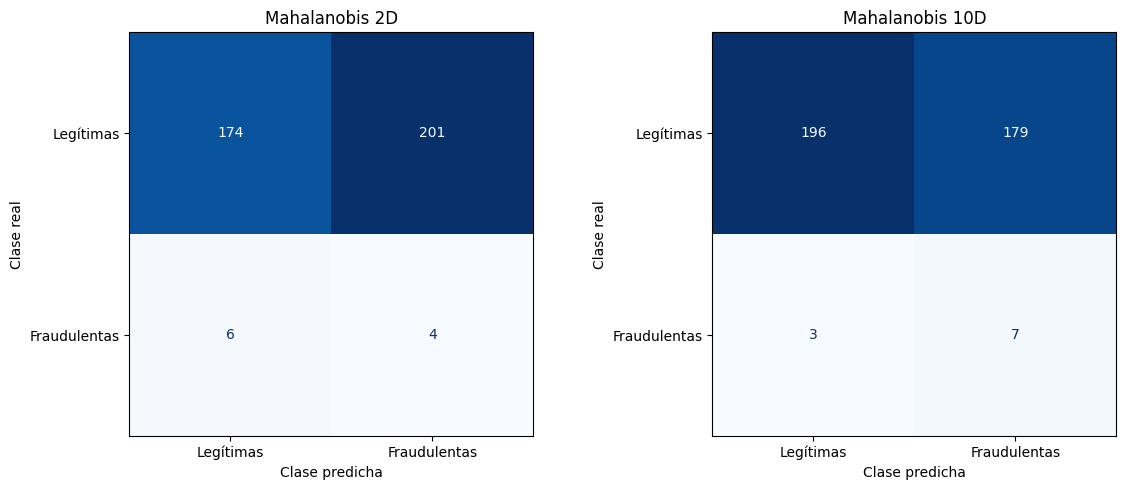

In [101]:
# Comparar matrices de confusión
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

configuraciones = [
    (y_pred_test_maha_2d, "Mahalanobis 2D"),
    (y_pred_test_maha_10d, "Mahalanobis 10D")
]

for ax, (predicciones, titulo) in zip(
    axes, configuraciones
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones,
        labels=[0, 1],
        display_labels=["Legítimas", "Fraudulentas"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

In [102]:
# Tabla comparativa
df_comparativa_maha = pd.concat(
    [
        df_test_maha_2d,
        df_test_maha_10d
    ],
    ignore_index=True
)

columnas_reporte = [
    "componentes",
    "varianza_explicada_pct",
    "percentil",
    "radio",
    "TN",
    "FP",
    "FN",
    "TP",
    "precision",
    "recall",
    "f1_score",
    "fpr",
    "balanced_accuracy",
    "tiempo_inferencia_s"
]

display(
    df_comparativa_maha[columnas_reporte].round(6)
)

,componentes,varianza_explicada_pct,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,balanced_accuracy,tiempo_inferencia_s
0,2,22.020426,50.0,1.022705,174,201,6,4,0.019512,0.4,0.037209,0.536000,0.432000,0.000412
1,10,66.923009,50.0,2.727340,196,179,3,7,0.037634,0.7,0.071429,0.477333,0.611333,0.000552


Los resultados muestran que Mahalanobis mejora su capacidad de detección al incrementar la dimensionalidad de 2 a 10 componentes principales, aunque su desempeño todavía es insuficiente para un sistema de detección de fraude

### Conclusiones de Mahalanobis

El incremento de 2 a 10 componentes principales permitió
aumentar la varianza explicada del 22.02% al 66.92%.

Sobre el conjunto de prueba, el Recall aumentó del 40%
al 70%, mientras que la tasa de falsos positivos disminuyó
del 53.60% al 47.73%.

El F1-score aumentó de 0.0372 a 0.0714 y la Balanced
Accuracy pasó del 43.20% al 61.13%.

Estos resultados sugieren que los componentes principales
adicionales contienen información relevante para la
detección de fraude.

Sin embargo, ambos modelos presentan una baja precisión
y una elevada tasa de falsos positivos.

La naturaleza elipsoidal de las regiones de Mahalanobis
limita su capacidad para representar distribuciones
con estructuras geométricas complejas.

Esto motiva la implementación del kernel de
Christoffel-Darboux como método alternativo de detección
de anomalías.